In [25]:
import numpy as np
import matplotlib.pyplot as plt

In [26]:
x = np.array([-0.5, 1, 0.5])
#sigmoid = lambda z: 1 / (1 + np.exp(-z))

print(sigmoid(x))

[0.37754067 0.73105858 0.62245933]


Não se utiliza EQM (valore bem baixos) na regressão logística e sim a entropia cruzada.

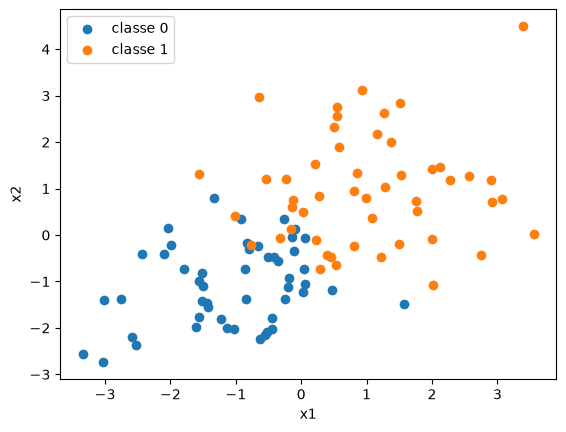

In [27]:
rng = np.random.default_rng(42)
m_por_classe = 50
X0 = rng.normal(loc=[-1,-1], scale=1.2, size=(m_por_classe, 2)) # Classe 0
X1 = rng.normal(loc=[1,1], scale=1.2, size=(m_por_classe, 2)) # Classe 1

X_dados = np.vstack([X0,X1])
y = np.concatenate([np.zeros(m_por_classe), np.ones(m_por_classe)])

plt.scatter(X_dados[y == 0, 0], X_dados[y == 0, 1], label="classe 0")
plt.scatter(X_dados[y == 1, 0], X_dados[y == 1, 1], label="classe 1")
plt.xlabel("x1"); plt.ylabel("x2"); plt.legend(); plt.show()


In [28]:
idx = rng.permutation(len(y))
corte = int(0.8 * len(y))
treino, teste = idx[:corte], idx[corte:] # 80 treino e 20 teste

uns = np.ones((X_dados.shape[0], 1))
X = np.hstack([uns, X_dados])

X_treino, y_treino = X[treino], y[treino]
X_teste, y_teste = X[teste], y[teste]
print(X_treino.shape, y_treino.shape)

beta = np.zeros(X.shape[1])
print(beta)

(80, 3) (80,)
[0. 0. 0.]


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def custo(p, y, eps=1e-12):
    p= np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def gradient(X, p, y):
    m = len(y)
    return X.T @ (p - y) / m

In [30]:
alpha, epocas = 0.1, 1000
beta = np.zeros(X_treino.shape[1])
historico = []

for epoca in range(epocas):
    z = X_treino @ beta
    p = sigmoid(z)
    historico.append(custo(p, y_treino))
    beta = beta - alpha * gradient(X_treino, p, y_treino)
    if epoca % 200 == 0:
        print(f"época {epoca:4d}  custo {historico[-1]:.4f}")

print("beta:", beta.round(3))

época    0  custo 0.6931
época  200  custo 0.2102
época  400  custo 0.1960
época  600  custo 0.1905
época  800  custo 0.1878
beta: [0.257 2.116 2.653]


In [31]:
p_teste = sigmoid(X_teste @ beta)
y_pred = (p_teste >= 0.5).astype(int)

acc_teste = np.mean(y_pred == y_teste)
acc_treino = np.mean((sigmoid(X_treino @ beta) >= 0.5) == y_treino)

print(p_teste[:5].round(3), y_pred[:5], y_teste[:5].astype(int))
print(f"acurácia treino {acc_treino:.3f}  |  teste {acc_teste:.3f}")

[1.    0.954 0.79  0.006 0.881] [1 1 1 0 1] [1 1 1 0 1]
acurácia treino 0.900  |  teste 0.900


In [34]:
y_pred_02 = (p_teste >= 0.2).astype(int)
y_pred_0999999 = (p_teste >= 0.999999).astype(int)

acc_treino_02 = np.mean((sigmoid(X_treino @ beta) >= 0.2) == y_treino)
acc_treino_0999999 = np.mean((sigmoid(X_treino @ beta) >= 0.999999) == y_treino)

print(p_teste[:5].round(3), y_pred_02[:5], y_teste[:5].astype(int))
print(f"acurácia treino {acc_treino_02:.3f}  |  teste {acc_teste:.3f}")

print(p_teste[:5].round(3), y_pred_0999999[:5], y_teste[:5].astype(int))
print(f"acurácia treino {acc_treino_0999999:.3f}  |  teste {acc_teste:.3f}")

[1.    0.954 0.79  0.006 0.881] [1 1 1 0 1] [1 1 1 0 1]
acurácia treino 0.887  |  teste 0.900
[1.    0.954 0.79  0.006 0.881] [1 0 0 0 0] [1 1 1 0 1]
acurácia treino 0.537  |  teste 0.900


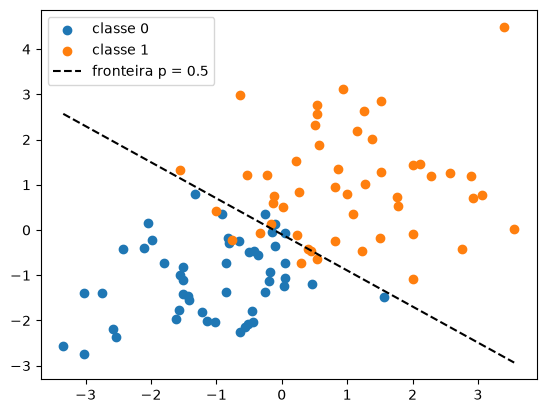

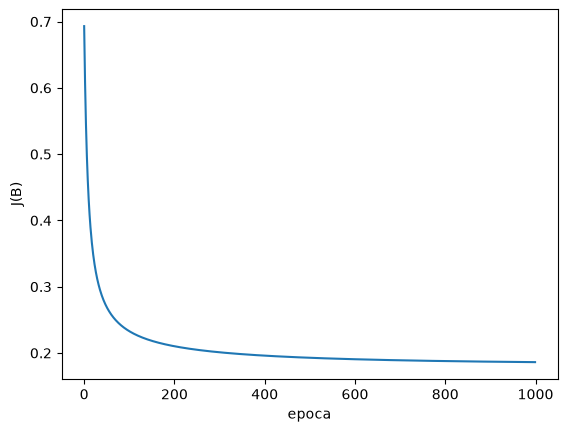

In [36]:
b0, b1, b2 = beta
x1 = np.linspace(X_dados[:, 0].min(), X_dados[:, 0].max(), 100)
x2 = -(b0 + b1 *x1) / b2

plt.scatter(X_dados[y == 0, 0], X_dados[y == 0, 1], label="classe 0")
plt.scatter(X_dados[y == 1, 0], X_dados[y == 1, 1], label="classe 1")
plt.plot(x1,x2, "k--", label="fronteira p = 0.5")
plt.legend(); plt.show()

plt.plot(historico) # Curva de Custo
plt.xlabel("epoca"); plt.ylabel("J(B)"); plt.show()